# Bets e inadimplência: painel UF × mês

**Pergunta:** nas UFs onde o interesse por apostas cresceu mais que a média nacional, a inadimplência das famílias
subiu mais nos meses seguintes?

```
inad[uf, t] = β · trends[uf, t−k] + γ · selic[t] × pobreza[uf] + α_uf + δ_t + ε
```

- `inad`: carteira inadimplida / carteira ativa de pessoas físicas (SCR.data, BCB), em %.
- `trends`: índice comparável do Google Trends para apostas (ver `google_trends.ipynb`), **padronizado**.
  β é a variação da inadimplência, em pontos percentuais, quando o Trends da UF sobe 1 desvio-padrão.
- `α_uf` (efeito fixo de UF) absorve diferenças permanentes entre UFs (renda, estrutura de crédito).
- `δ_t` (efeito fixo de mês) absorve **tudo o que é nacional**: Selic, inflação, desemprego médio, programas
  como o Desenrola, Copas. É assim que os juros saem da conta.

Dados: `uv run python -m src.inadimplencia.scr_uf` e `uv run python -m src.exposicao.google_trends`.
O painel é montado por `src/painel.py`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import warnings

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl
import pyfixest as pf

from src.painel import FAIXAS, PLACEBO, SENSIVEIS, inadimplencia_uf, painel

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:.3f}".format)

## Decisões

**Período: jan/2022 a ago/2026.**
- Começa em 2022 para ficar fora da pandemia, seguindo a decisão do `analise.ipynb`: as carências e repactuações
  de 2020–21 distorcem a inadimplência.
- Termina em ago/2026, o último mês cheio antes da MP 1.394. O choque da MP é outra pergunta, a ser feita quando
  saírem os dados de out–dez/2026.

**Defasagem k.** No SCR, "inadimplida" significa atraso acima de 90 dias. Um aperto causado por apostas no mês t
só vira inadimplência por volta de t+3 ou mais. Estimamos k = 0, 3, 6 e 9 e não escolhemos um k "vencedor"
depois de ver os resultados. A especificação principal, **k = 6**, foi fixada antes de rodar: é o meio do
intervalo plausível (3 meses para virar atraso de 90 dias, mais alguns meses de rolagem no cartão e no cheque especial).

**Controle Selic × pobreza.** O efeito fixo de mês tira a Selic do nível, mas UFs mais pobres podem sentir mais os
juros, e UFs mais pobres também buscam mais por bets. Incluímos `selic[t] × pobreza[uf]`, com pobreza medida como
beneficiários do Bolsa Família / população em ago/2024 (centrada na média). O ideal seria renda de 2022 da PNAD,
mas o PBF share muda devagar e já está baixado.

**Erros-padrão.** Clusterizados por UF, porque há correlação serial dentro da UF. São só **27 clusters**, poucos
para a aproximação assintótica, então reportamos também o p-valor de **wild cluster bootstrap** (Rademacher,
9.999 réplicas).

**Pesos.** Principal: sem pesos, cada UF conta igual (a pergunta é sobre UFs, não sobre reais). Robustez:
ponderado pela carteira ativa.

In [2]:
p = painel(inadimplencia_uf())
print(f"{p['uf'].n_unique()} UFs × {p['mes'].n_unique()} meses = {p.height} obs  ({p['mes'].min()} a {p['mes'].max()})")
faltando = p.group_by("uf").len().filter(pl.col("len") < p["mes"].n_unique())
print("UFs com meses faltando:", faltando.to_dicts() or "nenhuma")
df = p.to_pandas()

27 UFs × 56 meses = 1512 obs  (2022-01 a 2026-08)
UFs com meses faltando: nenhuma


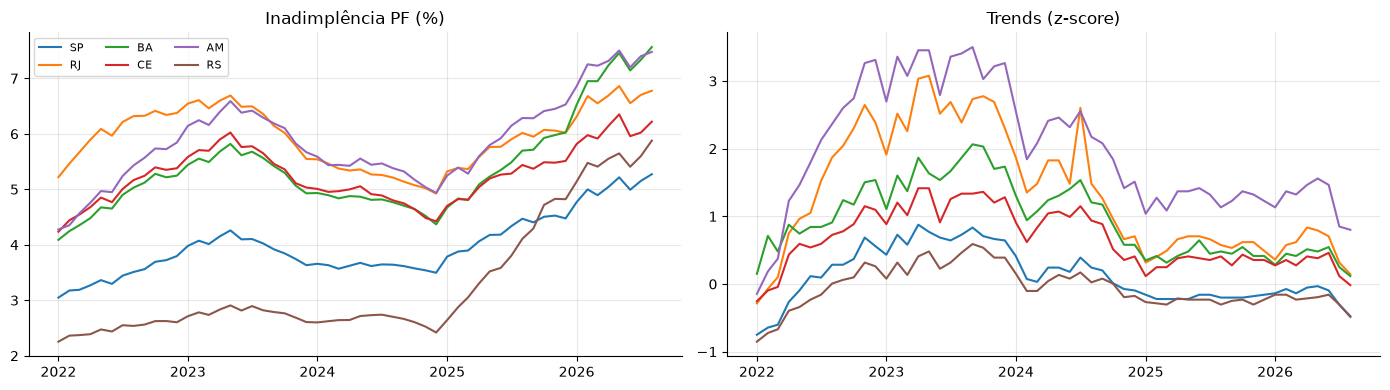

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for uf in ["SP", "RJ", "BA", "CE", "AM", "RS"]:
    d = p.filter(pl.col("uf") == uf)
    axes[0].plot(d["data"], d["inad"], label=uf)
    axes[1].plot(d["data"], d["trends"], label=uf)
axes[0].set_title("Inadimplência PF (%)"); axes[1].set_title("Trends (z-score)")
axes[0].legend(ncol=3, fontsize=8)
plt.tight_layout()

## Função de estimação

`estimar` roda a regressão e devolve coeficiente, erro-padrão clusterizado por UF, p-valor analítico e p-valor do
wild bootstrap. Semente fixa (42) para o bootstrap ser reprodutível.

In [4]:
def estimar(dados, y="inad", x="trends_l6", controles="selic_x_pobreza", fe="uf + mes", pesos=None, rotulo=None):
    fml = f"{y} ~ {x}" + (f" + {controles}" if controles else "") + f" | {fe}"
    d = dados.dropna(subset=[y, x])
    fit = pf.feols(fml, data=d, vcov={"CRV1": "uf_id"}, weights=pesos)
    t = fit.tidy().loc[x]
    # wild bootstrap não é suportado com pesos (WLS): nesse caso fica só o EP clusterizado
    p_boot = float("nan") if pesos else float(fit.wildboottest(param=x, reps=9999, seed=42)["Pr(>|t|)"])
    return {
        "modelo": rotulo or fml, "β": t["Estimate"], "ep": t["Std. Error"],
        "p": t["Pr(>|t|)"], "p_boot": p_boot, "n": fit._N,
    }

## 1. Resultado principal: defasagens 0, 3, 6 e 9

In [5]:
res = pd.DataFrame([estimar(df, x=f"trends_l{k}", rotulo=f"k = {k}") for k in (0, 3, 6, 9)]).set_index("modelo")
res

,β,ep,p,p_boot,n
modelo,,,,,
k = 0,-0.194,0.491,0.695,0.746,1512
k = 3,-0.199,0.445,0.659,0.740,1512
k = 6,-0.147,0.369,0.693,0.786,1512
k = 9,-0.090,0.283,0.753,0.857,1512


## 2. Placebo temporal: o Trends do futuro "prevê" a inadimplência de hoje?

Se β capta efeito das apostas, o Trends **6 meses à frente** não deveria explicar a inadimplência de hoje,
uma vez controlado o Trends defasado. Se explicar, há uma tendência comum por trás das duas séries
(ex.: uma UF em deterioração econômica que busca mais apostas *e* atrasa mais), e β não é efeito.

In [6]:
fit = pf.feols("inad ~ trends_l6 + trends_f6 + selic_x_pobreza | uf + mes", data=df.dropna(subset=["trends_f6"]), vcov={"CRV1": "uf_id"})
fit.tidy().loc[["trends_l6", "trends_f6"]]

,Estimate,Std. Error,t value,Pr(>|t|),2.5%,97.5%
Coefficient,,,,,,
trends_l6,-0.088,0.270,-0.328,0.746,-0.643,0.466
trends_f6,-0.214,0.397,-0.539,0.595,-1.031,0.603


## 3. Placebo por modalidade

**Decisão — grupos:**
- **Sensíveis** (crédito sem garantia, que a família deixa de pagar primeiro num aperto): cartão de crédito,
  empréstimo pessoal sem consignação, outros créditos (inclui cheque especial).
- **Placebo:** habitacional e veículos (com garantia real, o devedor prioriza para não perder o bem) e
  **consignado** (descontado direto da folha, não dá para deixar de pagar).
- **Rural** fica fora dos dois grupos, porque depende de safra e clima, não da liquidez da família.

Se as apostas apertam o orçamento, β deveria ser positivo nas sensíveis e ~0 no placebo.

In [7]:
linhas = []
for nome, mods in [("sensíveis", SENSIVEIS), ("placebo", PLACEBO)]:
    d = painel(inadimplencia_uf(pl.col("modalidade").is_in(mods))).to_pandas()
    linhas.append(estimar(d, rotulo=nome))
for m in SENSIVEIS + PLACEBO:
    d = painel(inadimplencia_uf(pl.col("modalidade") == m)).to_pandas()
    linhas.append(estimar(d, rotulo="  " + m.replace("PF - ", "")))
pd.DataFrame(linhas).set_index("modelo")

,β,ep,p,p_boot,n
modelo,,,,,
sensíveis,-0.200,0.413,0.633,0.733,1512
placebo,0.111,0.088,0.218,0.278,1512
Cartão de crédito,-0.002,0.201,0.990,0.989,1512
Empréstimo sem consignação em folha,-0.239,0.317,0.458,0.564,1512
Outros créditos,-0.259,0.916,0.779,0.895,1512
Habitacional,0.080,0.059,0.186,0.187,1512
Veículos,0.125,0.184,0.504,0.534,1512
Empréstimo com consignação em folha,0.098,0.088,0.276,0.315,1512


## 4. Gradiente de renda

Se o mecanismo é aposta, o efeito deveria ser maior em quem ganha menos: a mesma perda pesa mais no orçamento, e
os dados do BCB/DataSenado mostram a aposta concentrada nas faixas mais baixas.

**Decisão:** as faixas "Sem rendimento" e "Indisponível" ficam fora. A composição delas é instável: "sem rendimento"
foi de 3% para 16% de inadimplência só em 2025, o que indica reclassificação de clientes, não comportamento.

In [8]:
linhas = []
for nome, faixas in FAIXAS.items():
    d = painel(inadimplencia_uf(pl.col("porte").is_in(faixas))).to_pandas()
    linhas.append(estimar(d, rotulo=nome))
    d = painel(inadimplencia_uf(pl.col("porte").is_in(faixas) & pl.col("modalidade").is_in(SENSIVEIS))).to_pandas()
    linhas.append(estimar(d, rotulo=nome + " × sensíveis"))
pd.DataFrame(linhas).set_index("modelo")

,β,ep,p,p_boot,n
modelo,,,,,
ate_2sm,-0.323,0.282,0.262,0.280,1512
ate_2sm × sensíveis,-0.280,0.393,0.483,0.495,1512
2_a_5sm,-0.167,0.268,0.539,0.616,1512
2_a_5sm × sensíveis,-0.219,0.384,0.574,0.588,1512
acima_5sm,-0.165,0.433,0.707,0.801,1512
acima_5sm × sensíveis,-0.240,0.543,0.662,0.830,1512


## 5. Robustez

- **Sem o controle Selic × pobreza:** mostra quanto esse controle mexe em β.
- **Ponderado pela carteira ativa:** dá mais peso às UFs grandes (SP, RJ, MG). O `pyfixest` não faz wild
  bootstrap com pesos, então essa linha tem só o p-valor clusterizado (`p_boot` = NaN).
- **Tendência linear por UF** (`C(uf):t`): absorve trajetórias próprias de cada UF. É uma exigência forte, porque
  come parte da variação de interesse se o efeito das bets for gradual.

In [9]:
df["t"] = df.groupby("uf").cumcount()
pd.DataFrame([
    estimar(df, rotulo="principal (k=6)"),
    estimar(df, controles=None, rotulo="sem Selic × pobreza"),
    estimar(df, pesos="carteira_ativa", rotulo="ponderado pela carteira"),
    estimar(df, controles="selic_x_pobreza + C(uf):t", rotulo="+ tendência linear por UF"),
]).set_index("modelo")

,β,ep,p,p_boot,n
modelo,,,,,
principal (k=6),-0.147,0.369,0.693,0.786,1512
sem Selic × pobreza,-0.130,0.364,0.725,0.796,1512
ponderado pela carteira,-0.140,0.376,0.712,NaN,1512
+ tendência linear por UF,-0.192,0.239,0.431,0.491,1512


## 6. Diagnóstico: quanta variação sobra para identificar β?

Os efeitos fixos tiram a variação comum. Se quase toda a variação do Trends for nacional, sobra pouco para estimar
β, e o β "por 1 DP" do Trends bruto exagera o tamanho do choque relevante. Aqui medimos a variação **residual**
(depois de tirar UF e mês) e reescalamos o intervalo de confiança para um choque de 1 DP *residual*, que é o
tamanho típico de uma UF se descolando da média nacional.

A autocorrelação do resíduo testa se essa variação é sinal ou ruído amostral do Google. Ruído puro teria
autocorrelação próxima de zero.

In [10]:
f_x = pf.feols("trends_l6 ~ 1 | uf + mes", data=df)
res_x = df["trends_l6"] - f_x.predict()
f_y = pf.feols("inad ~ 1 | uf + mes", data=df)
res_y = df["inad"] - f_y.predict()
df["_rx"] = res_x.values
autocorr = df.sort_values(["uf", "data"]).groupby("uf")["_rx"].apply(lambda s: s.autocorr(1)).mean()

b, ep = res.loc["k = 6", "β"], res.loc["k = 6", "ep"]
dp = res_x.std()
diag = pd.Series({
    "R² do Trends explicado pelos FE": 1 - res_x.var() / df["trends_l6"].var(),
    "DP residual do Trends (z)": dp,
    "autocorrelação lag-1 do resíduo": autocorr,
    "DP residual da inadimplência (p.p.)": res_y.std(),
    "inadimplência média (%)": df["inad"].mean(),
    "IC95 inferior (p.p. por 1 DP residual)": (b - 1.96 * ep) * dp,
    "IC95 superior (p.p. por 1 DP residual)": (b + 1.96 * ep) * dp,
})
diag

R² do Trends explicado pelos FE           0.916
DP residual do Trends (z)                 0.241
autocorrelação lag-1 do resíduo           0.791
DP residual da inadimplência (p.p.)       0.676
inadimplência média (%)                   4.581
IC95 inferior (p.p. por 1 DP residual)   -0.210
IC95 superior (p.p. por 1 DP residual)    0.139
dtype: float64

## Leitura

**Não encontramos associação entre interesse por apostas e inadimplência entre UFs.** Em nenhuma especificação
β é distinguível de zero (p e p_boot > 0,18 em todas). As estimativas pontuais são levemente negativas.

**Mas é um nulo informativo, não falta de poder.** O diagnóstico mostra que:
- os efeitos fixos absorvem ~92% da variação do Trends, porque o boom e a queda das bets foram essencialmente nacionais;
- a variação que sobra é **sinal, não ruído** (autocorrelação ~0,8);
- para uma UF que se descola 1 DP residual da média nacional, o IC95 vai de cerca de **−0,21 a +0,14 p.p.** de
  inadimplência, para uma média de ~4,6%. Efeitos acima de ~0,14 p.p. (~3% do nível) estão descartados.

**Os placebos e o gradiente de renda vão na mesma direção:** nada nas modalidades sensíveis, nada nas faixas de
renda baixa. O placebo temporal (Trends futuro) também é nulo, então não há sinal de tendência comum enviesando.

**O que este resultado NÃO diz:**
1. **Não diz que bets não endividam pessoas.** Diz que, no agregado da UF, diferenças de intensidade de apostas
   não se traduzem em diferenças de inadimplência bancária. O dano pode estar concentrado demais (uma minoria de
   apostadores pesados) para aparecer numa média de UF.
2. **O Trends mede busca, não gasto.** Erro de medida na exposição atenua β em direção a zero. Com uma medida de
   gasto por UF (pedido de LAI à SPA), o teste ficaria mais forte.
3. **Inadimplência bancária é só um canal.** Atrasos em contas de consumo (luz, aluguel, crediário de loja,
   agiota) não aparecem no SCR.
4. **O efeito nacional fica sem identificação.** Ao controlar efeito fixo de mês, jogamos fora justamente a variação
   nacional (o boom 2022–23). Se as bets elevaram a inadimplência *de todas as UFs juntas*, este desenho não vê. É
   por isso que o choque da MP 1.394 importa: ele cria variação na *intensidade* de exposição perdida entre UFs.

**Próximo teste:** quando o SCR de out–dez/2026 sair (~fev/2027), estimar se as UFs com maior `trends_2024` tiveram
**queda** relativa da inadimplência depois da proibição (diff-in-diff com intensidade).